# 데이터 도구 실습: 주문 서비스에서 고객별 합계 내기

**이 노트북에서 할 일**

1. 01~04절의 도구로 부품 함수를 만들고, 고객 파일과 주문 서비스의 데이터를 데이터베이스 하나에 모읍니다.
2. 고객 파일 `customers.csv`로 조립 함수를 실행해, 고객별 합계와 확인한 값을 기록장에 적습니다(실행 1).
3. 고객 파일 이름 하나만 02절의 `all_customers.csv`로 바꿔 다시 실행하고, 두 기록장을 비교합니다(실행 2).

**준비물** — API 키 불필요. 인터넷에 있는 서비스에는 접속하지 않습니다.
04절처럼 이 컴퓨터 안에 연습용 주문 서비스를 켰다가 마지막 셀에서 끕니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**기준 버전** — 01~05절과 같은 실습 폴더에 고정한 pandas 3.0.5와 httpx 0.28.1을 씁니다.
교재 출력은 Python 3.12.13과, 그 Python에 들어 있는 SQLite 3.53.1로 만들었습니다. 다른 버전은 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch04-data-tools`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.
새 문법과 새 라이브러리 기능은 없습니다. 강사와 함께 셀을 차례로 실행하며, 따로 내는 과제는 없습니다.

## 오늘 볼 그림

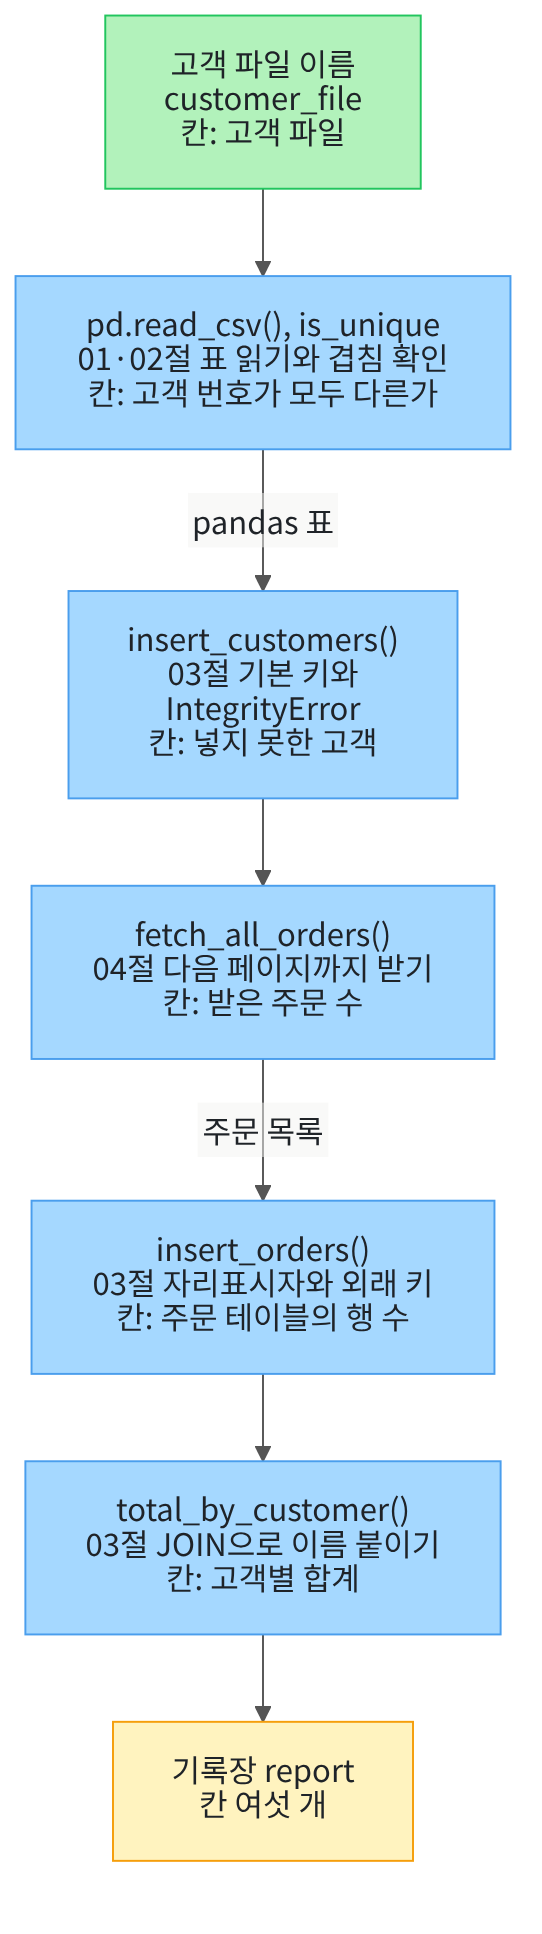

위에서 아래로 읽습니다. 파란 상자는 이 노트북에서 부르는 코드와 함수이고, 상자마다 쓰는 절과 기록장에 적는 칸을 적었습니다.
맨 위 초록 상자는 실행 1과 실행 2에서 바꾸는 값인 고객 파일 이름입니다. 맨 아래 노란 상자는 결과를 적는 기록장입니다.

## 1. 준비

이 절도 01~04절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다. 폴더 이름의 앞머리만 `ch04-06-`으로 바꿨습니다.

05절은 실습 폴더의 `data` 폴더에서 작업했습니다. 그 폴더의 `article-text.json`은 Ch 5가 읽으므로, 이번 실습은 그 폴더를 쓰지 않습니다.

In [1]:
# 실습 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch04-06-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 도구 세 가지 불러오기

이번 실습은 01·02절의 pandas, 03절의 sqlite3, 04절의 httpx를 한 노트북에서 함께 씁니다.
세 import 줄과 버전을 출력하는 줄은 앞 절에서 쓴 모양 그대로입니다.

실행 전에 예상합니다. 버전은 01·03·04절에서 출력한 값과 같을 것입니다.

In [2]:
# 01·02절 pandas, 03절 sqlite3, 04절 httpx를 불러오고 버전을 확인합니다
import pandas as pd
import sqlite3
import httpx

print("pandas 버전:", pd.__version__)
print("SQLite 버전:", sqlite3.sqlite_version)
print("httpx 버전:", httpx.__version__)

pandas 버전: 3.0.5
SQLite 버전: 3.53.1
httpx 버전: 0.28.1


**결과 읽기** — 출력은 `pandas 버전: 3.0.5`, `SQLite 버전: 3.53.1`, `httpx 버전: 0.28.1`입니다.
세 값 모두 앞 절에서 본 버전과 같습니다. SQLite 버전은 Python 설치본에 따라 다를 수 있습니다.

## 3. 실습 주제 — 주문 서비스에서 고객별 합계 내기

고객 명단은 02절처럼 CSV 파일로 받습니다. 주문은 04절의 연습용 주문 서비스가 페이지로 나눠 줍니다.
이번 실습은 두 데이터를 03절의 데이터베이스 하나에 모으고, 고객별 주문 합계를 냅니다.
합계만 보지 않고, 중간에 확인한 값을 기록장에 함께 남깁니다.

Ch 19 01절은 실습 폴더 `data_tools.py`의 `fetch_orders()`를 모델이 고르는 도구로 다시 씁니다.
01절 함수와 하는 일은 같고, 상태를 키워드 인자 `status=`로 받는 모양입니다.

실행 1과 실행 2는 고객 파일 이름 하나만 다릅니다. 실행 1은 고객 두 명이 한 줄씩 든 `customers.csv`입니다.
실행 2는 02절 Before에서 쓴 `all_customers.csv`로, 김하나 줄이 두 번 들어 있습니다.

02절 Before에서는 이 파일을 주문 표에 `merge()`로 바로 이었습니다. 그때 연결한 표는 5행, 금액 합계는 136000이었습니다.
이번에는 같은 파일을 데이터베이스에 먼저 넣으면 무엇이 달라지는지 봅니다.

## 4. 재료 만들기 — 고객 파일 두 개

02절과 같은 글로 고객 파일 두 개를 씁니다. 파일 `customers.csv`는 C001 김하나, C002 이두리 두 줄입니다.
파일 `all_customers.csv`는 그 뒤에 C001 김하나 줄이 한 번 더 있습니다.

실행 전에 예상합니다. 파일 목록에 두 CSV 파일 이름이 알파벳 순서로 나올 것입니다.

In [3]:
# 02절과 같은 고객 파일 두 개를 씁니다. 둘째 파일은 C001 줄이 두 번 들어 있습니다
customer_text = """customer_id,name
C001,김하나
C002,이두리
"""
with open("customers.csv", "w", encoding="utf-8") as file:
    file.write(customer_text)
all_customer_text = customer_text + "C001,김하나\n"
with open("all_customers.csv", "w", encoding="utf-8") as file:
    file.write(all_customer_text)
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['all_customers.csv', 'customers.csv']


**결과 읽기** — 파일 목록은 `['all_customers.csv', 'customers.csv']`입니다.
둘째 파일의 글은 첫 파일 글 끝에 김하나 줄 하나를 Ch 3에서 쓴 글자 `+`로 이어 붙여 만들었습니다. 끝의 `\n`은 05절에서 본 줄바꿈 한 글자입니다.
두 파일은 02절에서 쓴 파일과 글이 같습니다.

## 5. 재료 만들기 — 연습용 주문 서비스 켜기(준비 코드)

아래 세 셀은 04절과 같은 **연습용 서버를 켜는 준비 코드**입니다. 줄마다 읽지 않아도 되고, 셀마다 하는 일만 확인하고 실행합니다.

첫 셀은 서비스가 페이지마다 보낼 주문 목록 글 두 개를 파일로 씁니다. 1쪽에는 주문 두 건, 2쪽에는 한 건이 있습니다.

In [4]:
# 연습용 서비스가 페이지마다 보낼 주문 목록 글 두 개를 파일로 씁니다(04절과 같음)
page_1_text = """{"orders": [
  {"order_id": "O101", "customer_id": "C001", "amount": 32000},
  {"order_id": "O102", "customer_id": "C002", "amount": 18000}
], "next_page": 2}"""
with open("page=1.json", "w", encoding="utf-8") as file:
    file.write(page_1_text)
page_2_text = """{"orders": [
  {"order_id": "O103", "customer_id": "C001", "amount": 27000}
], "next_page": null}"""
with open("page=2.json", "w", encoding="utf-8") as file:
    file.write(page_2_text)

둘째 셀은 04절의 서비스 프로그램 파일 `order_server.py`를 씁니다. 주소가 `/orders`이고 페이지 파일이 있으면 그 글을 보내는 프로그램입니다.

In [5]:
# 요청을 받아 파일 글을 보내는 서비스 프로그램을 order_server.py 파일로 씁니다(04절과 같음)
server_text = """import os
from wsgiref.simple_server import make_server

# 요청 하나가 올 때마다 이 함수가 불립니다
def answer(environ, start_response):
    # 주소 끝의 쿼리 문자열 page=1로 파일 page=1.json을 고릅니다
    file_name = environ["QUERY_STRING"] + ".json"
    if environ["PATH_INFO"] != "/orders" or not os.path.exists(file_name):
        start_response("404 Not Found", [("Content-Type", "application/json")])
        return [b'{"error": "not found"}']
    start_response("200 OK", [("Content-Type", "application/json")])
    with open(file_name, "rb") as file:
        return [file.read()]

# 포트 번호 0은 운영체제에게 비어 있는 번호를 골라 달라는 뜻입니다
server = make_server("127.0.0.1", 0, answer)
print(server.server_port, flush=True)
server.serve_forever()"""
with open("order_server.py", "w", encoding="utf-8") as file:
    file.write(server_text)

셋째 셀은 04절처럼 `subprocess.Popen()`으로 그 프로그램을 켜 두고, 서비스가 알려 준 포트 번호로 주소를 만듭니다.

In [6]:
# 서비스 프로그램을 따로 실행하고, 서비스가 알려 준 포트 번호로 주소를 만듭니다(04절과 같음)
import subprocess
import sys

# Popen()은 프로그램을 켜 두고 기다리지 않습니다. 서비스의 접속 기록(stderr)은 버립니다
server_process = subprocess.Popen(
    [sys.executable, "order_server.py"],
    stdout=subprocess.PIPE,
    stderr=subprocess.DEVNULL,
    text=True,
)
# 서비스가 켜지면서 출력한 첫 줄(포트 번호)을 읽습니다
port_text = server_process.stdout.readline().strip()
base_url = f"http://127.0.0.1:{port_text}"
print("서비스 주소:", base_url)

서비스 주소: http://127.0.0.1:41047


**결과 읽기** — 서비스 주소는 `http://127.0.0.1:`로 시작합니다. 콜론 뒤의 포트 번호는 실행할 때마다 달라서 교재와 다를 수 있습니다.
이제 서비스가 요청을 기다립니다.

## 6. 재료 만들기 — 같은 모양의 빈 데이터베이스 두 개

두 실행을 비교하려면 두 실행이 같은 상태에서 시작해야 합니다. 그래서 파일 `shop-1.db`와 `shop-2.db`에 같은 모양의 빈 테이블을 만듭니다.
반복문 `for`로 같은 SQL 문장을 두 파일에 한 번씩 실행합니다.

테이블은 03절과 같은 제약을 둡니다. 고객 번호는 고객 테이블의 기본 키이고, 주문 테이블에서는 외래 키입니다.
04절 서비스의 주문에는 상태 칸이 없어서, 주문 테이블에서 `status` 열만 뺐습니다. 열 정의는 한 줄에 몰아 적었습니다.

실행 전에 예상합니다. 출력은 없고, 파일 목록 끝에 데이터베이스 파일 두 개가 더해질 것입니다.

In [7]:
# 두 데이터베이스 파일에 03절과 같은 제약을 둔 고객 테이블과 주문 테이블을 만듭니다
customer_table_sql = """CREATE TABLE customers (
    customer_id TEXT PRIMARY KEY, name TEXT NOT NULL)"""
order_table_sql = """CREATE TABLE orders (
    order_id TEXT PRIMARY KEY, customer_id TEXT NOT NULL, amount INTEGER NOT NULL,
    FOREIGN KEY (customer_id) REFERENCES customers (customer_id))"""
for database_name in ["shop-1.db", "shop-2.db"]:
    connection = sqlite3.connect(database_name)
    connection.execute(customer_table_sql)
    connection.execute(order_table_sql)
    connection.commit()
    connection.close()
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['all_customers.csv', 'customers.csv', 'order_server.py', 'page=1.json', 'page=2.json', 'shop-1.db', 'shop-2.db']


**결과 읽기** — 파일 목록은 `['all_customers.csv', 'customers.csv', 'order_server.py', 'page=1.json', 'page=2.json', 'shop-1.db', 'shop-2.db']`입니다.
앞의 두 CSV 파일과 서비스 파일 세 개 뒤에 데이터베이스 파일 두 개가 생겼습니다. 두 파일의 테이블은 아직 비어 있습니다.

## 7. 부품 준비 — 고객 표를 데이터베이스에 넣기

첫 부품 `insert_customers()`는 pandas 표를 받습니다. 표를 01절의 `to_dict(orient="records")`로 딕셔너리 목록으로 바꾸고, 고객을 한 명씩 넣습니다.
넣는 SQL은 03절의 `INSERT INTO`에 자리표시자 `?`를 둔 모양입니다. 물음표가 두 개라서, 값 목록에도 고객 번호와 이름 두 값을 차례로 넣습니다.

이미 있는 고객 번호를 넣으면 03절에서 본 `sqlite3.IntegrityError`가 납니다. 한 명이 막혀도 나머지를 넣도록, 넣는 줄만 이 오류 이름으로 받습니다.
막힌 고객 번호는 목록에 모아 반환합니다.

매개변수 `customers`에는 pandas 표가 들어옵니다. 05절 `find_text()`처럼 이 자료형의 이름은 다루지 않아 타입힌트를 적지 않았습니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [8]:
# pandas 표의 고객을 한 명씩 고객 테이블에 넣고, 기본 키에 막힌 고객 번호 목록을 반환합니다
def insert_customers(database_name: str, customers) -> list:
    records = customers.to_dict(orient="records")
    connection = sqlite3.connect(database_name)
    rejected_ids = []
    for record in records:
        values = [record["customer_id"], record["name"]]
        try:
            connection.execute("INSERT INTO customers VALUES (?, ?)", values)
        except sqlite3.IntegrityError as error:
            print("고객 넣기 오류:", record["customer_id"], error)
            rejected_ids.append(record["customer_id"])
    connection.commit()
    connection.close()
    return rejected_ids

**결과 읽기** — 예상대로 출력이 없습니다. 고객을 넣는 일은 함수를 부를 때 실행됩니다.

## 8. 부품 준비 — 주문을 끝까지 받아 넣기

둘째 부품은 04절 After의 `fetch_all_orders()`를 그대로 가져옵니다. 다음 페이지 번호가 `None`이 될 때까지 요청해, 주문을 모두 모아 반환합니다.
요청할 때마다 요청한 페이지와 다음 페이지 번호를 출력합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [9]:
# 04절 함수: 다음 페이지 번호가 None이 될 때까지 차례로 요청해, 모든 주문을 모아 반환합니다
def fetch_all_orders(orders_url: str) -> list:
    all_orders = []
    page = 1
    while page is not None:
        response = httpx.get(orders_url, params={"page": page}, timeout=2.0)
        response.raise_for_status()
        body = response.json()
        print("요청한 페이지:", page, "/ 다음 페이지 번호:", body["next_page"])
        for order in body["orders"]:
            all_orders.append(order)
        # 응답이 알려 준 다음 페이지 번호로 바꿉니다. 마지막 페이지에서는 None입니다
        page = body["next_page"]
    return all_orders

**결과 읽기** — 예상대로 출력이 없습니다. 반환하는 주문 딕셔너리의 키는 `order_id`, `customer_id`, `amount`입니다.

셋째 부품 `insert_orders()`는 받은 주문 목록을 주문 테이블에 넣습니다. 03절처럼 연결을 연 뒤 외래 키 검사를 먼저 켭니다.
넣는 SQL의 물음표는 세 개이고, 값 목록에는 주문 번호, 고객 번호, 금액을 차례로 넣습니다.
넣은 뒤에는 03절 마지막 셀처럼 `SELECT * FROM orders`로 행을 읽어, 테이블의 행 수를 반환합니다.

외래 키 검사가 켜져 있으면 고객 테이블에 없는 번호의 주문은 넣을 수 없습니다. 그래서 조립 함수는 고객을 먼저 넣고 주문을 넣습니다.
이번 서비스의 주문은 고객 번호가 모두 C001이나 C002라서, 이 함수에는 오류를 받는 줄을 두지 않았습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [10]:
# 주문 목록을 주문 테이블에 넣고, 넣은 뒤 테이블의 행 수를 반환합니다
def insert_orders(database_name: str, orders: list) -> int:
    connection = sqlite3.connect(database_name)
    # 03절처럼 이 연결에서 외래 키 검사를 켭니다
    connection.execute("PRAGMA foreign_keys = ON")
    for order in orders:
        values = [order["order_id"], order["customer_id"], order["amount"]]
        connection.execute("INSERT INTO orders VALUES (?, ?, ?)", values)
    connection.commit()
    cursor = connection.execute("SELECT * FROM orders")
    rows = cursor.fetchall()
    connection.close()
    return len(rows)

**결과 읽기** — 예상대로 출력이 없습니다. 주문을 받는 부품과 넣는 부품을 정의했습니다.

## 9. 부품 준비 — 고객별 합계 내기

넷째 부품 `total_by_customer()`는 03절의 `JOIN`으로 주문마다 고객 이름을 붙여 읽습니다.
03절 `find_customer_orders()`의 SQL에서 고객 번호 조건 `WHERE`를 빼고, 이름과 금액 두 열만 고른 모양입니다.
읽은 행 수는 03절 라벨 그대로 「연결한 행 수:」로 출력합니다.

합계는 이름을 키로 둔 딕셔너리에 모읍니다. Ch 2 03절의 `get(키, 기본값)`은 키가 아직 없으면 기본값을 반환합니다.
그래서 처음 나온 이름도 0에 금액을 더해 시작합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# 주문 테이블과 고객 테이블을 고객 번호로 이어 읽고, 고객 이름별 금액 합계를 반환합니다
def total_by_customer(database_name: str) -> dict:
    sql = """SELECT customers.name, orders.amount
    FROM orders JOIN customers ON orders.customer_id = customers.customer_id
    ORDER BY orders.order_id"""
    connection = sqlite3.connect(database_name)
    cursor = connection.execute(sql)
    rows = cursor.fetchall()
    connection.close()
    print("연결한 행 수:", len(rows))
    totals = {}
    for name, amount in rows:
        # 이름이 처음 나오면 get()이 0을 반환해, 0에 금액을 더합니다
        totals[name] = totals.get(name, 0) + amount
    return totals

**결과 읽기** — 예상대로 출력이 없습니다. 반환하는 딕셔너리의 키는 고객 이름, 값은 그 고객의 금액 합계입니다.

## 10. 기록 장치 — 기록장 출력 함수

두 실행을 비교하려면 결과를 같은 칸에 적어 둬야 합니다. Ch 2 13절처럼 딕셔너리를 기록장으로 씁니다.
기록장을 칸마다 한 줄씩 출력하는 함수는 Ch 2 13절의 `print_report()`를 그대로 가져옵니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [12]:
# Ch 2 13절 함수: 기록장 딕셔너리의 칸을 한 줄에 하나씩 출력합니다
def print_report(report):
    # items()는 키와 값의 짝을 차례로 내놓습니다
    for key, value in report.items():
        print(key, "|", value)

**결과 읽기** — 예상대로 출력이 없습니다. 이 함수는 실행 1과 실행 2에서 한 번씩 부릅니다.

## 11. 조립하기 — 고객 파일 이름에서 기록장까지

조립 함수 `run_pipeline()`은 고객 파일 이름, 데이터베이스 파일 이름, 주문 주소를 받습니다.
고객 파일을 01절의 `pd.read_csv()`로 읽고, 부품 네 개를 차례로 부르며 반환값을 기록장에 적습니다.
줄마다 붙인 주석에 그 줄이 쓰는 절을 적었습니다.

표를 넣기 전에 02절의 `is_unique`로 고객 번호가 모두 다른지 먼저 적어 둡니다.
기록장 칸은 여섯 개입니다. 고객 파일, 고객 번호가 모두 다른가, 넣지 못한 고객, 받은 주문 수, 주문 테이블의 행 수, 고객별 합계입니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [13]:
# 조립: 고객 파일 읽기 → 고객 넣기 → 주문 받기 → 주문 넣기 → 고객별 합계까지 기록장에 적습니다
def run_pipeline(customer_file: str, database_name: str, orders_url: str) -> dict:
    report = {"고객 파일": customer_file}
    # 01절 CSV 읽기, 02절 기본 키로 쓸 열이 모두 다른지 확인
    customers = pd.read_csv(customer_file)
    report["고객 번호가 모두 다른가"] = customers["customer_id"].is_unique
    # 03절 기본 키와 IntegrityError
    report["넣지 못한 고객"] = insert_customers(database_name, customers)
    # 04절 다음 페이지 번호를 따라 끝까지 받기
    orders = fetch_all_orders(orders_url)
    report["받은 주문 수"] = len(orders)
    # 03절 자리표시자와 외래 키
    report["주문 테이블의 행 수"] = insert_orders(database_name, orders)
    # 03절 JOIN으로 고객 이름 붙이기
    report["고객별 합계"] = total_by_customer(database_name)
    return report

**결과 읽기** — 예상대로 출력이 없습니다. 조립이 끝났습니다. 이제 파일 이름과 주소만 넣어 부르면 됩니다.

## 12. 실행 1 — 고객 파일 customers.csv

변수 `orders_url`에 04절처럼 서비스 주소와 `/orders`를 이어 담습니다.
고객 파일 `customers.csv`와 데이터베이스 `shop-1.db`로 조립 함수를 부르고, 기록장을 칸별로 출력합니다.

실행 전에 예상합니다. 고객 번호가 모두 다르므로 `True`이고, 넣지 못한 고객은 빈 목록일 것입니다.
04절 After처럼 페이지 두 개를 요청해 주문 세 건을 받을 것입니다.
합계는 02·03절처럼 김하나 59000, 이두리 18000일 것입니다.

In [14]:
# 실행 1: 고객 파일 customers.csv와 빈 데이터베이스 shop-1.db로 조립 함수를 부릅니다
orders_url = base_url + "/orders"
customer_file = "customers.csv"
report_1 = run_pipeline(customer_file, "shop-1.db", orders_url)
print("기록장:")
print_report(report_1)

요청한 페이지: 1 / 다음 페이지 번호: 2
요청한 페이지: 2 / 다음 페이지 번호: None
연결한 행 수: 3
기록장:
고객 파일 | customers.csv
고객 번호가 모두 다른가 | True
넣지 못한 고객 | []
받은 주문 수 | 3
주문 테이블의 행 수 | 3
고객별 합계 | {'김하나': 59000, '이두리': 18000}


**결과 읽기** — 기록장은 `고객 번호가 모두 다른가 | True`, `넣지 못한 고객 | []`, `받은 주문 수 | 3`입니다.
이어서 `주문 테이블의 행 수 | 3`, `고객별 합계 | {'김하나': 59000, '이두리': 18000}`입니다. 예상과 같습니다.

기록장 위쪽에는 부품이 출력한 줄이 있습니다. 요청 줄은 `요청한 페이지: 1 / 다음 페이지 번호: 2`와 `요청한 페이지: 2 / 다음 페이지 번호: None`입니다.
그 아래 `연결한 행 수: 3`은 주문 세 건에 고객 이름이 한 번씩 붙었다는 뜻입니다.
「고객 넣기 오류:」 줄은 없으므로 오류를 받는 줄은 실행되지 않았습니다.

## 13. 실행 2 — 고객 파일 이름 하나만 바꾸기

바꾸는 값은 고객 파일 이름 하나입니다. 02절 Before의 `all_customers.csv`로 바꾸고, 같은 조립 함수를 부릅니다.
데이터베이스 `shop-2.db`는 재료 단계에서 `shop-1.db`와 같은 모양으로 만든 빈 파일입니다. 두 실행의 데이터를 나눠 두려고 파일만 따로 두었습니다.

실행 전에 예상합니다. 김하나 줄이 두 번이라 고객 번호가 모두 다른가는 `False`일 것입니다.
두 번째 C001 줄은 기본 키에 막혀, 넣지 못한 고객 목록에 들어갈 것입니다.

주문 서비스는 같으므로 받은 주문 수와 주문 테이블의 행 수는 3일 것입니다.
고객 테이블에 김하나가 한 번만 들어가면 연결한 행 수도 3이고, 합계도 실행 1과 같을 것입니다.

In [15]:
# 실행 2: 고객 파일 이름 하나만 all_customers.csv로 바꾸고, 같은 모양의 빈 shop-2.db로 부릅니다
customer_file = "all_customers.csv"
report_2 = run_pipeline(customer_file, "shop-2.db", orders_url)
print("기록장:")
print_report(report_2)

고객 넣기 오류: C001 UNIQUE constraint failed: customers.customer_id
요청한 페이지: 1 / 다음 페이지 번호: 2
요청한 페이지: 2 / 다음 페이지 번호: None
연결한 행 수: 3
기록장:
고객 파일 | all_customers.csv
고객 번호가 모두 다른가 | False
넣지 못한 고객 | ['C001']
받은 주문 수 | 3
주문 테이블의 행 수 | 3
고객별 합계 | {'김하나': 59000, '이두리': 18000}


**결과 읽기** — 기록장은 `고객 번호가 모두 다른가 | False`, `넣지 못한 고객 | ['C001']`입니다.
나머지 칸은 `받은 주문 수 | 3`, `주문 테이블의 행 수 | 3`, `고객별 합계 | {'김하나': 59000, '이두리': 18000}`입니다. 예상과 같습니다.

출력 첫 줄은 `고객 넣기 오류: C001 UNIQUE constraint failed: customers.customer_id`입니다.
세 번째 줄의 C001이 기본 키에 막혔고, 함수가 오류를 받아 출력한 뒤 다음으로 넘어갔습니다.
그 뒤 `연결한 행 수: 3`도 실행 1과 같습니다.

## 14. 두 기록장 비교하기

두 기록장에서 같은 키의 값끼리 비교합니다. Ch 2 13절의 비교 셀과 같은 모양입니다. 기호 `!=`는 「두 값이 다른가」 비교입니다.

셀 끝의 검사 줄 `assert`는 두 실행의 고객별 합계가 같은지와, 실행 2에서 막힌 고객 번호를 확인합니다.
두 값은 파일과 서비스 글이 같으면 실행마다 같아야 합니다.
실행 전에 예상합니다. 달라진 칸은 앞의 세 칸이고, 뒤의 세 칸은 같을 것입니다.

In [16]:
# 두 기록장을 칸마다 비교하고, 달라진 칸의 수를 셉니다
changed_count = 0
for key, value_1 in report_1.items():
    value_2 = report_2[key]
    if value_1 != value_2:
        print("달라짐 |", key, "|", value_1, "->", value_2)
        changed_count += 1
    else:
        print("같음 |", key, "|", value_1)
print("달라진 칸 수:", changed_count)
# 두 실행의 합계가 같고, 실행 2에서 막힌 고객은 C001 하나여야 합니다
assert report_1["고객별 합계"] == report_2["고객별 합계"]
assert report_2["넣지 못한 고객"] == ["C001"]

달라짐 | 고객 파일 | customers.csv -> all_customers.csv
달라짐 | 고객 번호가 모두 다른가 | True -> False
달라짐 | 넣지 못한 고객 | [] -> ['C001']
같음 | 받은 주문 수 | 3
같음 | 주문 테이블의 행 수 | 3
같음 | 고객별 합계 | {'김하나': 59000, '이두리': 18000}
달라진 칸 수: 3


**결과 읽기** — 달라진 칸 수는 `3`입니다. 달라진 칸은 고객 파일, `고객 번호가 모두 다른가 | True -> False`, `넣지 못한 고객 | [] -> ['C001']`입니다.
같은 칸은 `같음 | 받은 주문 수 | 3`, `같음 | 주문 테이블의 행 수 | 3`, 고객별 합계입니다. 검사 줄 `assert`도 멈추지 않았습니다.

바꾼 값은 고객 파일 이름 하나이고, 함수와 서비스는 그대로입니다. 고객 파일의 겹친 줄은 앞의 두 단계에서만 드러났습니다.
주문 두 칸은 고객 파일과 관계없이 같았습니다. 기본 키가 겹친 줄을 막아, 연결한 행 수와 합계도 실행 1과 같았습니다.

## 15. 데이터베이스에 남은 고객 확인하기

실행 2의 고객 파일은 세 줄이었습니다. 데이터베이스 `shop-2.db`의 고객 테이블에는 몇 줄이 남았을까요?
01절의 `len()`으로 파일의 행 수를 세고, 03절처럼 `SELECT * FROM customers`로 테이블의 행을 읽어 나란히 봅니다.

실행 전에 예상합니다. 파일은 3행, 테이블은 2행일 것입니다.

In [17]:
# 실행 2의 고객 파일 행 수와, 데이터베이스 shop-2.db에 남은 고객 행을 나란히 봅니다
all_customers = pd.read_csv("all_customers.csv")
print("고객 파일의 행 수:", len(all_customers))
connection = sqlite3.connect("shop-2.db")
cursor = connection.execute("SELECT * FROM customers")
customer_rows = cursor.fetchall()
connection.close()
print("고객 테이블의 행:", customer_rows)
print("고객 테이블의 행 수:", len(customer_rows))

고객 파일의 행 수: 3
고객 테이블의 행: [('C001', '김하나'), ('C002', '이두리')]
고객 테이블의 행 수: 2


**결과 읽기** — 출력은 `고객 파일의 행 수: 3`과 `고객 테이블의 행 수: 2`입니다.
고객 테이블의 행은 `[('C001', '김하나'), ('C002', '이두리')]`로, 고객 번호마다 한 줄씩입니다.

그래서 03절의 `JOIN`이 주문마다 이름을 한 번씩만 붙였습니다. 02절 Before는 겹친 줄이 남은 표에 이어 5행이 되었습니다.

## 16. 연습용 서비스 끄기

연습이 끝났으니 5번에서 켠 서비스를 04절처럼 끕니다. 메서드 `terminate()`는 멈추라는 신호를 보내고, `wait()`는 끝날 때까지 기다립니다.

실행 전에 예상합니다. 서비스가 아직 켜져 있는지 묻는 줄에 `False`가 나올 것입니다.

In [18]:
# 5번에서 켠 연습용 주문 서비스를 끄고, 꺼질 때까지 기다립니다
server_process.terminate()
server_process.wait()
# poll()이 None이 아니면 프로그램이 끝난 것입니다
print("서비스가 아직 켜져 있는가:", server_process.poll() is None)

서비스가 아직 켜져 있는가: False


**결과 읽기** — 출력은 `서비스가 아직 켜져 있는가: False`입니다. 연습용 서비스가 꺼졌습니다.
다시 연습하려면 첫 셀부터 차례로 실행합니다. 임시 폴더는 매번 새로 만들어집니다.

실행 1·2 셀만 같은 데이터베이스 파일로 다시 실행하면, 고객은 넣기 오류로 기록되지만 주문은 첫 줄에서 `IntegrityError`로 멈춥니다.
이 동작은 같은 함수를 따로 실행해 확인했고, 이 노트북 출력에는 없습니다.

## 정리

- 01~04절의 도구를 부품 네 개와 조립 함수 하나로 묶었습니다. 고객 파일과 주문 서비스의 데이터를 데이터베이스에 모아 고객별 합계를 냈습니다.
- 실행 1(`customers.csv`)은 고객 번호가 모두 달랐고, 주문 3건이 모두 들어가 김하나 59000, 이두리 18000이었습니다.
- 실행 2에서 파일 이름만 `all_customers.csv`로 바꾸자 `False`와 막힌 고객 `['C001']`이 기록되었고, 주문 수와 합계는 같았습니다.

실행 환경은 Linux의 Python 3.12.13입니다. 패키지는 pandas 3.0.5와 httpx 0.28.1, SQLite는 3.53.1입니다. 요청은 이 컴퓨터 안의 연습용 서비스에만 보냈습니다.
번호는 같고 이름이 다른 겹친 줄, 고객 테이블에 없는 번호의 주문은 이번에 실행하지 않았습니다.

이 절로 Ch 4가 끝납니다. Ch 5 01절은 05절이 쓴 `article-text.json`의 `text` 칸을 읽어 토큰 수를 셉니다.